# DH Final Diagnostics — 20260722_v1985 (honest-mean tail variants, final grid)

Winner-selection notebook for the per-vintage tail-variant final grid at
`02-evaluate/20260722_v1985_final/`. 54,432/54,432 configs verified (21 tasks, ~62 min median; predictions ON, flat per-fold layout, ~307K files).

This run is complete — no missing configs. The gamma free+weight exclusion below is still offered because the family's IRLS fragility is a property of the estimator, not of the v2000 data (it happens to converge here).

New in this cycle's version (vs `notebooks/20260714_*/dh_final_diagnostics.ipynb`):

1. **Gamma free+weight exclusion toggle** — wholesale drop by threshold or in
   total, applied to `dh_results` before any ranking (see that cell's rationale).
2. **One-sweep prediction index + dual-format loader** — handles flat/sharded x
   per-fold/batched layouts; batched files are read once per config. No per-call
   globbing (the naive loader is minutes-vs-hours slower on the sharded layout).
3. **Two-stage ranking** — the storm-level machinery (trimmed calibration,
   IS/OOS divergence) runs only on a `TRIM_POOL_N` pre-TOPSIS pool; a full sweep
   at this grid's scale would be pointlessly expensive (20260714's grid was 4,608
   configs; this one is ~30x bigger).

Cross-vintage rule: the universal pick matches configs across vintages by
`CONFIG_COLS`, **never** by `mid` (the hash encodes the data-derived
`threshold_rate`, so identical configs hash differently per vintage).

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from idd_tc_mortality.select.model_query import ModelQuery
from idd_tc_mortality.select.model_selection import (
    CONFIG_COLS,
    DEFAULT_METRICS,
    CALIBRATION_METRICS,
    prepare_rankings_df,
    borda_rank,
    pareto_frontier,
    topsis_rank,
    pairwise_dominance_summary,
    cluster_configurations,
    winner_profile,
    kendall_tau_heatmap,
    prune_redundant_metrics
)
from idd_tc_mortality.viz.stage_plots import StagePlotter

from idd_tc_mortality.viz import screening as H

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
pd.options.display.max_columns = 80
pd.options.display.width = 160

## Paths

Edit the dates to point at the final run you want to inspect.

In [2]:
ROOT      = Path('/mnt/team/idd/pub/idd_tc_mortality')
EVAL_DATE = '20260722_v1985_final'   # tail-variant final grid (predictions ON)
DATA_DATE = '20260722_v1985'

RESULTS_PATH   = ROOT / '02-evaluate' / EVAL_DATE / 'dh_results.parquet'
EVAL_DIR       = ROOT / '02-evaluate' / EVAL_DATE
DATA_PATH      = ROOT / '00-data'     / DATA_DATE / 'input.parquet'
MODEL_PRED_DIR = EVAL_DIR / 'model_predictions'
MANIFEST_PATH  = EVAL_DIR / 'manifest.json'

for pth in (RESULTS_PATH, EVAL_DIR, DATA_PATH, MODEL_PRED_DIR, MANIFEST_PATH):
    assert pth.exists(), f'Missing: {pth}'
print('All paths resolve.')

All paths resolve.


## Load

In [3]:
dh_results = pd.read_parquet(RESULTS_PATH)
data       = pd.read_parquet(DATA_PATH)
obs        = data   # alias used by the prediction loaders below

print(f'dh_results : {dh_results.shape[0]:,} rows x {dh_results.shape[1]} cols')
print(f'training   : {data.shape[0]:,} rows x {data.shape[1]} cols')
print(f'fold_tags  : {dh_results["fold_tag"].value_counts().to_dict()}')
print(f'configs    : {dh_results.groupby(CONFIG_COLS, dropna=False).ngroups:,} unique')
print(f'thresholds : {sorted(dh_results["threshold_quantile"].unique())}')
print()
print('IS configs per (threshold, tail_family, tail_exposure_mode):')
print(dh_results[dh_results.fold_tag == 'insample']
      .groupby(['threshold_quantile', 'tail_family', 'tail_exposure_mode'])
      .size().to_string())

dh_results : 306,588 rows x 252 cols
training   : 3,024 rows x 14 cols
fold_tags  : {'insample': 54432, 'oos_seed4': 52813, 'oos_seed2': 52488, 'oos_seed0': 49572, 'oos_seed3': 49248, 'oos_seed1': 48035}
configs    : 54,432 unique
thresholds : [np.float64(0.7), np.float64(0.85)]

IS configs per (threshold, tail_family, tail_exposure_mode):
threshold_quantile  tail_family         tail_exposure_mode
0.70                gamma               free+weight           3888
                                        weight                3888
                    gpd_trunc           free+weight           3888
                    log_logistic_cens   free+weight           3888
                    log_logistic_trunc  free+weight           3888
                    lognormal           free+weight           3888
                                        weight                3888
0.85                gamma               free+weight           3888
                                        weight                3

## Gamma free+weight exclusion

Root cause (2026-08-03 session): statsmodels' gamma IRLS has no step-length
control, and on log-link fits of tail excess rates spanning ~8 decades it
oscillates whenever `log_exposed` enters X as a free covariate
(`free+weight`). On v2000@0.70, 5 of 9 covariate cells diverge outright (the
4,400 configs missing from that run — sentinel fits, silently skipped) and 3
of the 4 surviving cells are non-converged oscillation stops that DID write
rows. Convergence is not persisted to `dh_results.parquet`, so rows from
oscillating fits are indistinguishable from good ones — the honest unit of
exclusion is the whole family x exposure-mode block.

- `None`   — keep everything
- `'all'`  — drop every gamma + free+weight config at any threshold (default)
- `[0.70]` — drop only at the listed threshold(s)

Gamma cells in other exposure modes (`excluded`, `weight`) converge and are
untouched.

In [4]:
DROP_GAMMA_FREE_WEIGHT = 'all'   # TUNE: None | 'all' | list of thresholds, e.g. [0.70]

if DROP_GAMMA_FREE_WEIGHT is not None:
    drop_mask = (
        (dh_results['tail_family'] == 'gamma')
        & (dh_results['tail_exposure_mode'] == 'free+weight')
    )
    if DROP_GAMMA_FREE_WEIGHT != 'all':
        wanted = {round(float(q), 2) for q in DROP_GAMMA_FREE_WEIGHT}
        drop_mask &= dh_results['threshold_quantile'].round(2).isin(wanted)

    print('Dropping gamma + free+weight rows, by threshold:')
    counts = (dh_results.loc[drop_mask, 'threshold_quantile']
              .value_counts().sort_index())
    print(counts.to_string() if len(counts) else '  (nothing matched)')

    n_before = len(dh_results)
    dh_results = dh_results[~drop_mask].copy()
    print(f'\n{n_before - len(dh_results):,} rows dropped; {len(dh_results):,} remain')

    remaining = dh_results[dh_results['tail_family'] == 'gamma']
    print('\nremaining gamma rows by (threshold, exposure_mode):')
    print(remaining.groupby(['threshold_quantile', 'tail_exposure_mode'])
          .size().to_string())
else:
    print('No gamma free+weight exclusion applied.')

Dropping gamma + free+weight rows, by threshold:
threshold_quantile
0.70    19116
0.85    18792

37,908 rows dropped; 268,680 remain

remaining gamma rows by (threshold, exposure_mode):
threshold_quantile  tail_exposure_mode
0.70                weight                20578
0.85                weight                14822


## Build the rankings dataframe

`prepare_rankings_df(..., subset='oos')` gives one row per config with OOS
metrics averaged across seeds. Then cull: drop configs with any non-finite
OOS metric (failed folds) and configs outside the calibration gate.

In [5]:
df_oos = prepare_rankings_df(dh_results, subset='oos')
print(f'Before cull: {len(df_oos):,} configs')

# Drop configs with any non-finite OOS metric (failed folds).
oos_numeric = [c for c in df_oos.columns
               if c.endswith('_oos') and pd.api.types.is_numeric_dtype(df_oos[c])]
finite_mask = np.isfinite(df_oos[oos_numeric].to_numpy()).all(axis=1)
n_failed = int((~finite_mask).sum())
df_oos = df_oos[finite_mask].copy()
print(f'After non-finite cull: {len(df_oos):,} configs ({n_failed:,} dropped as failures)')

# Calibration gate — TUNE on the ratio distribution. The refined stage used
# (0.1, 2.0); the 20260714 post-2000 final used an asymmetric (0.05, 1.1).
RATIO_BOUNDS = (0.1, 2.0)   # TUNE
df_oos = df_oos[df_oos['full_pred_obs_ratio_oos'].between(*RATIO_BOUNDS)].copy()
print(f'After calibration gate [{RATIO_BOUNDS[0]}, {RATIO_BOUNDS[1]}]: '
      f'{len(df_oos):,} configs')

print('\nPost-cull count per threshold:')
print(df_oos['threshold_quantile'].value_counts().sort_index().to_string())

Before cull: 46,008 configs
After non-finite cull: 45,766 configs (242 dropped as failures)
After calibration gate [0.1, 2.0]: 38,071 configs

Post-cull count per threshold:
threshold_quantile
0.70    20329
0.85    17742


### Convergence gate — still N/A, now with a known consequence

The re-fit-in-evaluate pipeline persists no per-component convergence flags,
so non-converged fits are invisible in `dh_results` — this is exactly why the
gamma free+weight exclusion above operates wholesale rather than per-fit.
Persisting the four per-component `converged` flags as columns is queued for a
future cycle.

## Per-rule winner trajectories

For each threshold, the configs that win at coverage level 1, 5, 10, 15, 20
(argmax of `full_coverage_rate_L_oos`) and on the mean across all 20 levels,
with their full 1..20 trajectories.

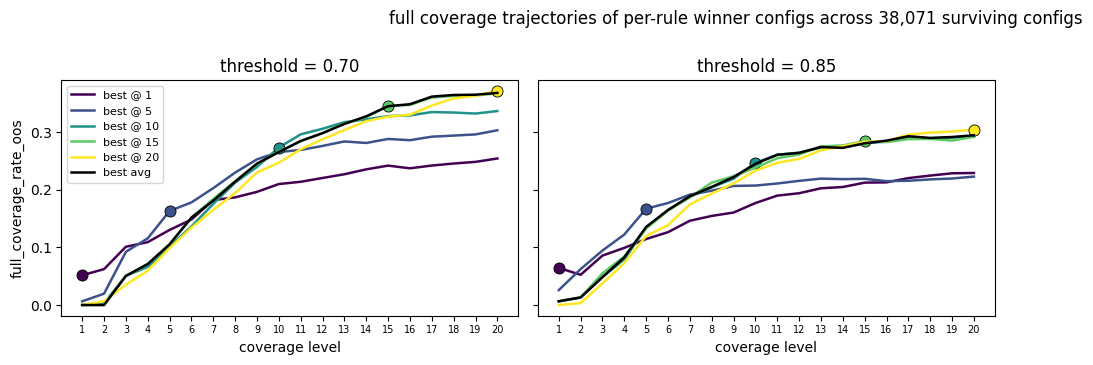


Winner configs per (threshold, rule):
 threshold      rule s1_family s1_exposure_mode                                                                 s1_cov s2_family s2_exposure_mode                                                                s2_cov  bulk_family bulk_exposure_mode                                                               bulk_cov        tail_family tail_exposure_mode                                                                tail_cov
      0.70  best @ 1     logit             free  {"basin": true, "is_island": false, "sdi": true, "wind_speed": false}     logit             free {"basin": false, "is_island": false, "sdi": true, "wind_speed": true} scaled_logit               free {"basin": false, "is_island": false, "sdi": true, "wind_speed": false}  log_logistic_cens        free+weight    {"basin": true, "is_island": true, "sdi": false, "wind_speed": true}
      0.70  best @ 5     logit             free   {"basin": true, "is_island": true, "sdi": true, "wind

In [6]:
winner_records = H.threshold_winner_panels(df_oos)
plt.show()

print('\nWinner configs per (threshold, rule):')
print(winner_records.to_string(index=False))

## Per-row diagnostics — `mid` reconstruction

`dh_results.parquet` stores spec attributes but not the MD5 `model_id` used
as the filename prefix in `model_predictions/`. Rebuild it via a lookup
against this run's manifest, then attach as a `mid` column on `df_oos`.

In [7]:
import json
from idd_tc_mortality.cache import model_id as compute_model_id

manifest = json.loads(MANIFEST_PATH.read_text())

# (component, threshold, family, exposure_mode, cov_str) -> full spec dict.
spec_lookup: dict[tuple, dict] = {}
for cid, spec in manifest.items():
    if not isinstance(spec, dict):
        continue
    if spec.get('fold_tag', 'is') != 'is':
        continue
    cov_str = json.dumps(spec.get('covariate_combo', {}), sort_keys=True)
    key = (
        spec.get('component'),
        spec.get('threshold_quantile'),  # None for s1
        spec.get('family'),
        spec.get('exposure_mode'),
        cov_str,
    )
    spec_lookup[key] = spec


def _row_to_mid(row: pd.Series) -> str:
    q = row['threshold_quantile']
    s1 = spec_lookup[('s1',   None, row['s1_family'],   row['s1_exposure_mode'],   row['s1_cov'])]
    s2 = spec_lookup[('s2',   q,    row['s2_family'],   row['s2_exposure_mode'],   row['s2_cov'])]
    bk = spec_lookup[('bulk', q,    row['bulk_family'], row['bulk_exposure_mode'], row['bulk_cov'])]
    tl = spec_lookup[('tail', q,    row['tail_family'], row['tail_exposure_mode'], row['tail_cov'])]
    return compute_model_id(s1, s2, bk, tl)


df_oos['mid'] = df_oos.apply(_row_to_mid, axis=1)
print(f'mid attached. {df_oos["mid"].nunique():,} unique mids across {len(df_oos):,} configs.')

mid attached. 38,071 unique mids across 38,071 configs.


## Prediction index + loader (one sweep, all layouts/formats)

Final-run predictions exist in up to four shapes: flat vs `task_*`-sharded
directories x per-fold (`{mid}_{fold}_predictions.parquet`) vs batched
(`{mid}_predictions.parquet`, all fold_tags stacked). `build_pred_index`
sweeps the tree ONCE and maps `mid -> files`; the loader reads a batched file
once per config instead of 6 reads, and nothing ever globs per call (the
per-call `glob` in the naive approach is minutes-vs-hours at this scale).
Shards are scanned after the flat root so retried tasks' newer files win, and
the batched format is preferred when both exist. Prediction frames are
self-contained (predicted_rate, observed_rate, exposed, ...); only
`storm_id`/`deaths` are attached positionally from `input.parquet`.

In [8]:
import os, re

_PRED_RE = re.compile(r'^([0-9a-f]{32})(?:_(.+))?_predictions\.parquet$')


def build_pred_index(model_pred_dir):
    """mid -> {fold_tag_or_None: path}; the None key marks a batched file.

    NFS trap: calling e.is_dir() on every entry costs one lstat round-trip
    each (millions here -> tens of minutes). Match the filename pattern FIRST
    (pure string op, no stat); only the handful of task_* names get stat'd.
    """
    import time
    t0 = time.time()
    idx: dict = {}
    n_seen = 0
    shard_dirs = []
    for e in os.scandir(model_pred_dir):
        m = _PRED_RE.match(e.name)
        if m:
            idx.setdefault(m.group(1), {})[m.group(2)] = e.path
            n_seen += 1
            if n_seen % 200_000 == 0:
                print(f'  ...{n_seen:,} files indexed ({time.time()-t0:.0f}s)')
        elif e.name.startswith('task_') and e.is_dir():
            shard_dirs.append(e.path)
    for shard in sorted(shard_dirs):
        for e in os.scandir(shard):
            m = _PRED_RE.match(e.name)
            if m:
                idx.setdefault(m.group(1), {})[m.group(2)] = e.path
                n_seen += 1
                if n_seen % 200_000 == 0:
                    print(f'  ...{n_seen:,} files indexed ({time.time()-t0:.0f}s)')
    print(f'  {n_seen:,} files total in {time.time()-t0:.0f}s')
    return idx


PRED_INDEX = build_pred_index(MODEL_PRED_DIR)
n_batched = sum(1 for v in PRED_INDEX.values() if None in v)
print(f'{len(PRED_INDEX):,} mids indexed '
      f'({n_batched:,} with a batched file, {len(PRED_INDEX) - n_batched:,} per-fold only)')

have_preds = df_oos['mid'].isin(PRED_INDEX).sum()
print(f'prediction coverage: {have_preds:,} of {len(df_oos):,} post-cull configs')


def load_pred_frames(mid):
    """{fold_tag: prediction frame}, storm_id/deaths attached positionally."""
    files = PRED_INDEX[mid]
    if None in files:   # batched: one read serves every fold_tag
        stacked = pd.read_parquet(files[None])
        groups = {t: g.reset_index(drop=True)
                  for t, g in stacked.groupby('fold_tag', sort=False)}
    else:               # per-fold files
        groups = {t: pd.read_parquet(pth) for t, pth in files.items()}
    out = {}
    for tag, g in groups.items():
        if len(g) != len(obs):
            raise ValueError(f'{mid} {tag}: {len(g):,} rows != input {len(obs):,}')
        g = g.copy()
        g['storm_id'] = obs['storm_id'].values
        g['deaths']   = obs['deaths'].values
        out[tag] = g
    return out


def load_pred(mid, fold_tag):
    """One fold's predictions joined to full input metadata (winner deep-dives)."""
    g = load_pred_frames(mid)[fold_tag]
    j = obs.copy()
    j['predicted_rate'] = g['predicted_rate'].values
    for col in ('heldout_fold_tag', 'threshold_rate', 'fold_tag'):
        if col in g.columns:
            j[col] = g[col].values
    return j

  ...200,000 files indexed (0s)
  306,911 files total in 1s
54,432 mids indexed (0 with a batched file, 54,432 per-fold only)
prediction coverage: 38,071 of 38,071 post-cull configs


## Two-stage ranking: pre-TOPSIS pool, then storm-level machinery

The trimmed-calibration sweep reads parquets per config — affordable for
20260714's 4,608 configs, not for this grid. So: a cheap metric-only TOPSIS
picks the `TRIM_POOL_N` pool, and only the pool pays the storm-level cost.
Configs outside the pool keep NaN trim columns and drop out of the final
ranking (which runs on the pool).

In [9]:
TRIM_POOL_N = 4000   # TUNE: size of the storm-level pool

pre_metrics = {
    'tail_mae_rate_oos':         'lower',
    'tail_cor_rate_oos':         'higher',
    'full_mae_rate_oos':         'lower',
    'full_cor_rate_oos':         'higher',
    'full_zero_acc_oos':         'higher',
    'full_pred_obs_ratio_oos':   'calib',
    'full_coverage_rate_10_oos': 'higher',
    'fwd_coverage_rate_10_oos':  'higher',
}
pre_calib   = [k for k, v in pre_metrics.items() if v == 'calib' and k in df_oos.columns]
pre_present = {k: v for k, v in pre_metrics.items() if k in df_oos.columns}

pre_topsis, _ = topsis_rank(df_oos, pre_present, pre_calib, verbose=False)
pool_mids = set(pre_topsis.sort_values('topsis_rank')['mid'].head(TRIM_POOL_N))
df_pool = df_oos[df_oos['mid'].isin(pool_mids)].copy()
print(f'storm-level pool: {len(df_pool):,} of {len(df_oos):,} configs')
print('\npool composition per (threshold, tail_family):')
print(df_pool.groupby(['threshold_quantile', 'tail_family']).size().to_string())

storm-level pool: 4,000 of 38,071 configs

pool composition per (threshold, tail_family):
threshold_quantile  tail_family       
0.70                gamma                 587
                    gpd_trunc             661
                    log_logistic_cens      90
                    log_logistic_trunc    949
                    lognormal             628
0.85                gamma                 445
                    gpd_trunc             284
                    log_logistic_cens      64
                    log_logistic_trunc    292


## Drop-top-N trimmed calibration ratio

For every pool config, the obs/pred ratio after dropping the top-N storms by
observed deaths, N in {0, 5, 10, 25}. A config near 1 at `trim_n=0` but far at
`trim_n=5` (or vice versa) is mega-event-only or bulk-only calibrated; we want
configs near 1 across the sweep. Reads each config's predictions ONCE via the
index (batched = literally one parquet read).

In [10]:
from concurrent.futures import ProcessPoolExecutor, as_completed

N_SWEEP   = [0, 5, 10, 25]
N_WORKERS = 12


def _per_storm(pred_df):
    pred_df = pred_df.assign(pred_deaths=pred_df['predicted_rate'] * pred_df['exposed'])
    return (pred_df.groupby('storm_id', as_index=False)
            .agg(obs=('deaths', 'sum'), pred=('pred_deaths', 'sum'))
            .sort_values('obs', ascending=False))


def _trimmed(per_storm, drop_top_n):
    keep = per_storm.iloc[drop_top_n:]
    denom = keep['obs'].sum()
    return float(keep['pred'].sum() / denom) if denom > 0 else float('nan')


def trimmed_ratios_one_config(mid):
    frames  = load_pred_frames(mid)
    ps_is    = _per_storm(frames['insample']) if 'insample' in frames else None
    ps_seeds = [_per_storm(f) for tag, f in sorted(frames.items())
                if tag.startswith('oos_seed')]
    rows = []
    for n in N_SWEEP:
        per_seed = [_trimmed(ps, n) for ps in ps_seeds]
        rows.append({
            'mid': mid,
            'drop_top_n': n,
            'ratio_mean':   float(np.nanmean(per_seed)) if per_seed else float('nan'),
            'ratio_median': float(np.nanmedian(per_seed)) if per_seed else float('nan'),
            'ratio_is':     _trimmed(ps_is, n) if ps_is is not None else float('nan'),
        })
    return rows


records = []
mids = df_pool['mid'].tolist()
with ProcessPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = [pool.submit(trimmed_ratios_one_config, m) for m in mids]
    for i, fut in enumerate(as_completed(futures), start=1):
        records.extend(fut.result())
        if i % 500 == 0 or i == len(mids):
            print(f'  trimmed-ratio: {i}/{len(mids)} configs done')

  trimmed-ratio: 500/4000 configs done
  trimmed-ratio: 1000/4000 configs done
  trimmed-ratio: 1500/4000 configs done
  trimmed-ratio: 2000/4000 configs done
  trimmed-ratio: 2500/4000 configs done
  trimmed-ratio: 3000/4000 configs done
  trimmed-ratio: 3500/4000 configs done
  trimmed-ratio: 4000/4000 configs done


In [11]:
recs = pd.DataFrame(records)

trim_df_mean   = recs.pivot(index='mid', columns='drop_top_n', values='ratio_mean')
trim_df_median = recs.pivot(index='mid', columns='drop_top_n', values='ratio_median')
trim_df_is     = recs.pivot(index='mid', columns='drop_top_n', values='ratio_is')

trim_df_mean.columns   = [f'trim_n={n}_oos_mean'   for n in trim_df_mean.columns]
trim_df_median.columns = [f'trim_n={n}_oos_median' for n in trim_df_median.columns]
trim_df_is.columns     = [f'trim_n={n}_is'         for n in trim_df_is.columns]

df_oos = (df_oos
    .merge(trim_df_is,     left_on='mid', right_index=True, how='left')
    .merge(trim_df_mean,   left_on='mid', right_index=True, how='left')
    .merge(trim_df_median, left_on='mid', right_index=True, how='left')
)
# Refresh the pool view so it carries the trim columns.
df_pool = df_oos[df_oos['mid'].isin(pool_mids)].copy()
print(f'Trim columns merged. df_oos cols: {df_oos.shape[1]}; pool rows: {len(df_pool):,}')

Trim columns merged. df_oos cols: 145; pool rows: 4,000


## IS / OOS divergence

`is_oos_ratio_n=*` = `trim_n=*_is` / `trim_n=*_oos_median`. Near 1 = IS
calibration carries OOS. Also the max/mean |log| deviation of the OOS-median
trim ratios themselves across the N sweep.

In [12]:
for n in N_SWEEP:
    df_pool[f'is_oos_ratio_n={n}'] = (
        df_pool[f'trim_n={n}_is'] / df_pool[f'trim_n={n}_oos_median']
    )

ratio_cols = [f'is_oos_ratio_n={n}' for n in N_SWEEP]
df_pool['is_oos_max_log_dev']  = np.abs(np.log(df_pool[ratio_cols])).max(axis=1)
df_pool['is_oos_mean_log_dev'] = np.abs(np.log(df_pool[ratio_cols])).mean(axis=1)

log_dev = np.abs(np.log(df_pool[[f'trim_n={n}_oos_median' for n in N_SWEEP]]))
df_pool['oos_median_max_log_dev']  = log_dev.max(axis=1)
df_pool['oos_median_mean_log_dev'] = log_dev.mean(axis=1)
print('IS/OOS divergence columns attached to df_pool.')

IS/OOS divergence columns attached to df_pool.


## Pick your own metrics

Edit the dict — comment / uncomment — to define the set used by the Kendall
heatmap and the ranking below. Direction: `'lower'` / `'higher'` /
`'calib'` (closer to 1.0). Trim columns are available now.

In [13]:
metrics_to_use = {
    # ---- S1 (binary: P(deaths >= 1)) ----
    's1_auroc_oos':                  'higher',
    # 's1_brier_oos':                'lower',

    # ---- S2 (binary: P(rate >= thresh | deaths >= 1)) ----
    's2_auroc_oos':                  'higher',
    # 's2_brier_oos':                'lower',

    # ---- Bulk (regression on rate < thresh) ----
    'bulk_mae_rate_oos':             'lower',
    # 'bulk_cor_rate_oos':           'higher',

    # ---- Tail (regression on rate >= thresh) ----
    'tail_mae_rate_oos':             'lower',
    # 'tail_rmse_rate_oos':          'lower',
    'tail_cor_rate_oos':             'higher',

    # ---- Full (unconditional E[rate]) ----
    'full_mae_rate_oos':             'lower',
    # 'full_rmse_rate_oos':          'lower',
    'full_cor_rate_oos':             'higher',
    'full_zero_acc_oos':             'higher',
    'full_pred_obs_ratio_oos':       'calib',
    'full_coverage_rate_10_oos':     'higher',
    'full_coverage_count_10_oos':    'higher',

    # ---- Forward (stage-conditional aggregate) ----
    'fwd_mae_rate_oos':              'lower',
    'fwd_pred_obs_ratio_oos':        'calib',
    'fwd_coverage_rate_10_oos':      'higher',
    'fwd_coverage_count_10_oos':     'higher',

    # ---- Storm-level (pool-only columns) ----
    'trim_n=10_oos_median':          'calib',
    'trim_n=10_is':                  'calib',
}

calib_present   = [k for k, v in metrics_to_use.items()
                   if v == 'calib' and k in df_pool.columns]
metrics_present = {k: v for k, v in metrics_to_use.items()
                   if k in df_pool.columns}

print(f'Active rank metrics ({len(metrics_present)}):')
for m, d in metrics_present.items():
    print(f'  {m:35s}  {d}')
print(f'\nActive calibration metrics ({len(calib_present)}):')
for c in calib_present:
    print(f'  {c}  (closer to 1.0)')

missing = [k for k in metrics_to_use if k not in df_pool.columns]
if missing:
    print(f'\n[note] {len(missing)} requested metrics not in df_pool (skipped): {missing}')

Active rank metrics (17):
  s1_auroc_oos                         higher
  s2_auroc_oos                         higher
  bulk_mae_rate_oos                    lower
  tail_mae_rate_oos                    lower
  tail_cor_rate_oos                    higher
  full_mae_rate_oos                    lower
  full_cor_rate_oos                    higher
  full_zero_acc_oos                    higher
  full_pred_obs_ratio_oos              calib
  full_coverage_rate_10_oos            higher
  full_coverage_count_10_oos           higher
  fwd_mae_rate_oos                     lower
  fwd_pred_obs_ratio_oos               calib
  fwd_coverage_rate_10_oos             higher
  fwd_coverage_count_10_oos            higher
  trim_n=10_oos_median                 calib
  trim_n=10_is                         calib

Active calibration metrics (4):
  full_pred_obs_ratio_oos  (closer to 1.0)
  fwd_pred_obs_ratio_oos  (closer to 1.0)
  trim_n=10_oos_median  (closer to 1.0)
  trim_n=10_is  (closer to 1.0)


## Kendall τ — prune redundant metrics on the pool

In [14]:
print(f'Computing rank correlations on {len(df_pool):,} configs x '
      f'{len(metrics_present)} metrics')
tau_df = kendall_tau_heatmap(df_pool, metrics_present, calib_present, plot=False, verbose=False)
final_metrics_present, prune_log = prune_redundant_metrics(tau_df, metrics_present, threshold=0.7)
tau_df = kendall_tau_heatmap(df_pool, final_metrics_present, calib_present, plot=False, verbose=False)
print('kept after pruning:')
for m in final_metrics_present:
    print(f'  {m}')

Computing rank correlations on 4,000 configs x 17 metrics
step 1: |τ|=0.810  trim_n=10_oos_median (0.214) vs trim_n=10_is (0.199)  → drop trim_n=10_oos_median
step 2: |τ|=0.703  full_mae_rate_oos (0.364) vs fwd_coverage_rate_10_oos (0.350)  → drop full_mae_rate_oos
kept after pruning:
  s1_auroc_oos
  s2_auroc_oos
  bulk_mae_rate_oos
  tail_mae_rate_oos
  tail_cor_rate_oos
  full_cor_rate_oos
  full_zero_acc_oos
  full_pred_obs_ratio_oos
  full_coverage_rate_10_oos
  full_coverage_count_10_oos
  fwd_mae_rate_oos
  fwd_pred_obs_ratio_oos
  fwd_coverage_rate_10_oos
  fwd_coverage_count_10_oos
  trim_n=10_is


## Winners by method

Borda and TOPSIS on the pool with the pruned metric set; group summaries by
(threshold, tail_family, exposure modes).

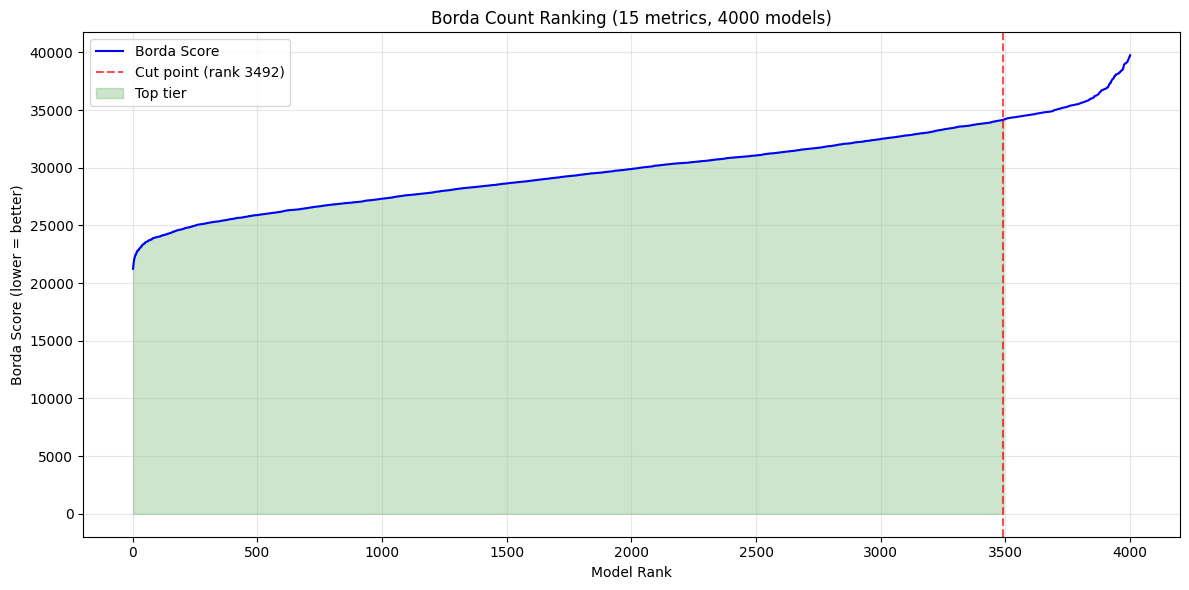


=== Borda Count Summary ===
Total models: 4000
Metrics used: 15
Suggested cutpoint: rank 3492 (top 3492 models)
Top tier Borda range: 21250.5 - 34164.0
Bottom tier starts at: 34165.5


In [20]:
borda_df, _  = borda_rank(df_pool, final_metrics_present, calib_present)
top_borda_df = borda_df[borda_df['borda_rank'] <= 200].copy()


In [21]:
topsis_df, _  = topsis_rank(df_pool, final_metrics_present, calib_present, verbose=False)
top_topsis_df = topsis_df[topsis_df['topsis_rank'] <= 200].copy()


In [22]:
import json

def decode_cov_columns(df):
    for stage in ['s1', 's2', 'bulk', 'tail']:
        col = f'{stage}_cov'
        for cov in ['basin', 'is_island', 'sdi', 'wind_speed']:
            df[f'{stage}_{cov}'] = df[col].apply(
                lambda x: (x if isinstance(x, dict) else json.loads(x)).get(cov, False)
            )
    return df

top_topsis_df = decode_cov_columns(top_topsis_df)
for stage in ['s1', 's2', 'bulk', 'tail']:
    covs = ['basin', 'is_island', 'sdi', 'wind_speed']
    top_topsis_df[f'{stage}_pattern'] = top_topsis_df.apply(
        lambda row: '+'.join(c for c in covs if row[f'{stage}_{c}']), axis=1
    )


## Picking table

Top pool configs by `topsis_rank` with stage covs, family/exposure choices,
and the storm-level diagnostics in one place. The pick rule is NOT baked in —
sort and filter interactively. Columns for the "no worse than any other"
defense: `topsis_rank`, `full_coverage_rate_*_oos`, `trim_n=*_oos_median`,
`is_oos_max_log_dev`, `oos_median_max_log_dev`.

In [23]:
if 'topsis_rank' not in df_pool.columns:
    df_pool = df_pool.merge(
        topsis_df[['mid', 'topsis_rank', 'topsis_score']],
        on='mid', how='left',
    )

picking_cols = [
    'mid', 'threshold_quantile',
    's1_family', 's1_exposure_mode', 's1_cov',
    's2_family', 's2_exposure_mode', 's2_cov',
    'bulk_family', 'bulk_exposure_mode', 'bulk_cov',
    'tail_family', 'tail_exposure_mode', 'tail_cov',
    'topsis_rank', 'topsis_score',
    'full_pred_obs_ratio_oos',
    'full_coverage_rate_5_oos', 'full_coverage_rate_10_oos',
    'full_coverage_rate_20_oos',
    'trim_n=0_oos_median',  'trim_n=5_oos_median',
    'trim_n=10_oos_median', 'trim_n=25_oos_median',
    'trim_n=0_is', 'trim_n=5_is', 'trim_n=10_is', 'trim_n=25_is',
    'oos_median_max_log_dev', 'is_oos_max_log_dev',
]
picking_cols = [c for c in picking_cols if c in df_pool.columns]

picking_df = (df_pool[picking_cols]
              .sort_values('topsis_rank')
              .reset_index(drop=True))

TOP_N = 15
print(f'Top {TOP_N} by topsis_rank ({len(picking_df):,} pool configs total):')
print()
print(picking_df.head(TOP_N).round(3).to_string(index=False))

Top 15 by topsis_rank (4,000 pool configs total):

                             mid  threshold_quantile s1_family s1_exposure_mode                                                               s1_cov s2_family s2_exposure_mode                                                               s2_cov  bulk_family bulk_exposure_mode                                                               bulk_cov tail_family tail_exposure_mode                                                              tail_cov  topsis_rank  topsis_score  full_pred_obs_ratio_oos  full_coverage_rate_5_oos  full_coverage_rate_10_oos  full_coverage_rate_20_oos  trim_n=0_oos_median  trim_n=5_oos_median  trim_n=10_oos_median  trim_n=25_oos_median  trim_n=0_is  trim_n=5_is  trim_n=10_is  trim_n=25_is  oos_median_max_log_dev  is_oos_max_log_dev
9eb29519c3cb6f793028bd6f9a671325                 0.7     logit             free {"basin": true, "is_island": false, "sdi": true, "wind_speed": true}     logit             free {"basin"

In [19]:
# Alternate view: among the top-N by topsis_rank, re-sort by IS/OOS divergence
# to surface configs whose IS calibration transfers OOS most reliably.
N_SHORTLIST = 25
shortlist = picking_df.head(N_SHORTLIST).copy()
print(f'Among top {N_SHORTLIST} by topsis_rank, sorted by oos_median_max_log_dev:')
print()
print(shortlist
      .sort_values('oos_median_max_log_dev')
      .round(3)
      .to_string(index=False))

Among top 25 by topsis_rank, sorted by oos_median_max_log_dev:

                             mid  threshold_quantile s1_family s1_exposure_mode                                                               s1_cov s2_family s2_exposure_mode                                                               s2_cov  bulk_family bulk_exposure_mode                                                               bulk_cov tail_family tail_exposure_mode                                                              tail_cov  topsis_rank  topsis_score  full_pred_obs_ratio_oos  full_coverage_rate_5_oos  full_coverage_rate_10_oos  full_coverage_rate_20_oos  trim_n=0_oos_median  trim_n=5_oos_median  trim_n=10_oos_median  trim_n=25_oos_median  trim_n=0_is  trim_n=5_is  trim_n=10_is  trim_n=25_is  oos_median_max_log_dev  is_oos_max_log_dev
bdaedfae16001e9af23ca05e1d504566                 0.7     logit             free  {"basin": true, "is_island": true, "sdi": true, "wind_speed": true}     logit             

## Next: cross-vintage universal

Winners above are per-vintage. The universal pick matches configs across the
two vintages by `CONFIG_COLS` — **never** by `mid`: the hash encodes the
data-derived `threshold_rate`, so an identical covariate/family config hashes
differently per vintage. Pattern: `notebooks/20260714_combined_final_topsis.ipynb`.